## Part A: Generate geometric training data

In [1]:
# Imports and configuration

import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

PATCH_SIZE = 64
EMBEDDING_DIM = 64

Device: mps


In [2]:
# Generate random geometric objects

def generate_random_shape(size=64, rng=None):
    """
    Generate one synthetic binary shape.

    Returns
    -------
    mask : np.ndarray
        uint8 binary image with values 0 or 255.
    """
    if rng is None:
        rng = np.random.default_rng()

    mask = np.zeros((size, size), dtype=np.uint8)

    cx = cy = size // 2
    shape_type = int(rng.integers(0, 5))

    if shape_type == 0:
        # Circle
        radius = int(rng.integers(10, 23))
        cv2.circle(mask, (cx, cy), radius, 255, -1)

    elif shape_type == 1:
        # Ellipse
        axes = (
            int(rng.integers(10, 24)),
            int(rng.integers(7, 20)),
        )
        angle = float(rng.uniform(0, 180))
        cv2.ellipse(
            mask, (cx, cy), axes,
            angle, 0, 360, 255, -1
        )

    else:
        # Variable polygon
        if shape_type == 2:
            n_vertices = 3
        elif shape_type == 3:
            n_vertices = 4
        else:
            n_vertices = int(rng.integers(5, 11))

        angles = (
            np.linspace(0, 2*np.pi, n_vertices, endpoint=False)
            + rng.uniform(0, 2*np.pi)
        )

        radii = rng.uniform(11, 24, n_vertices)

        pts = np.column_stack([
            cx + radii*np.cos(angles),
            cy + radii*np.sin(angles)
        ]).astype(np.int32)

        cv2.fillPoly(mask, [pts], 255)

    return mask


def augment_shape(mask, rng=None):
    """
    Apply rotation, scaling, and mild translation.

    The underlying object identity is preserved.
    """
    if rng is None:
        rng = np.random.default_rng()

    h, w = mask.shape

    angle = float(rng.uniform(-180, 180))
    scale = float(rng.uniform(0.80, 1.15))

    M = cv2.getRotationMatrix2D(
        (w/2, h/2), angle, scale
    )

    M[:, 2] += rng.uniform(-3, 3, size=2)

    output = cv2.warpAffine(
        mask,
        M,
        (w, h),
        flags=cv2.INTER_LINEAR,
        borderValue=0,
    )

    return output.astype(np.float32) / 255.0

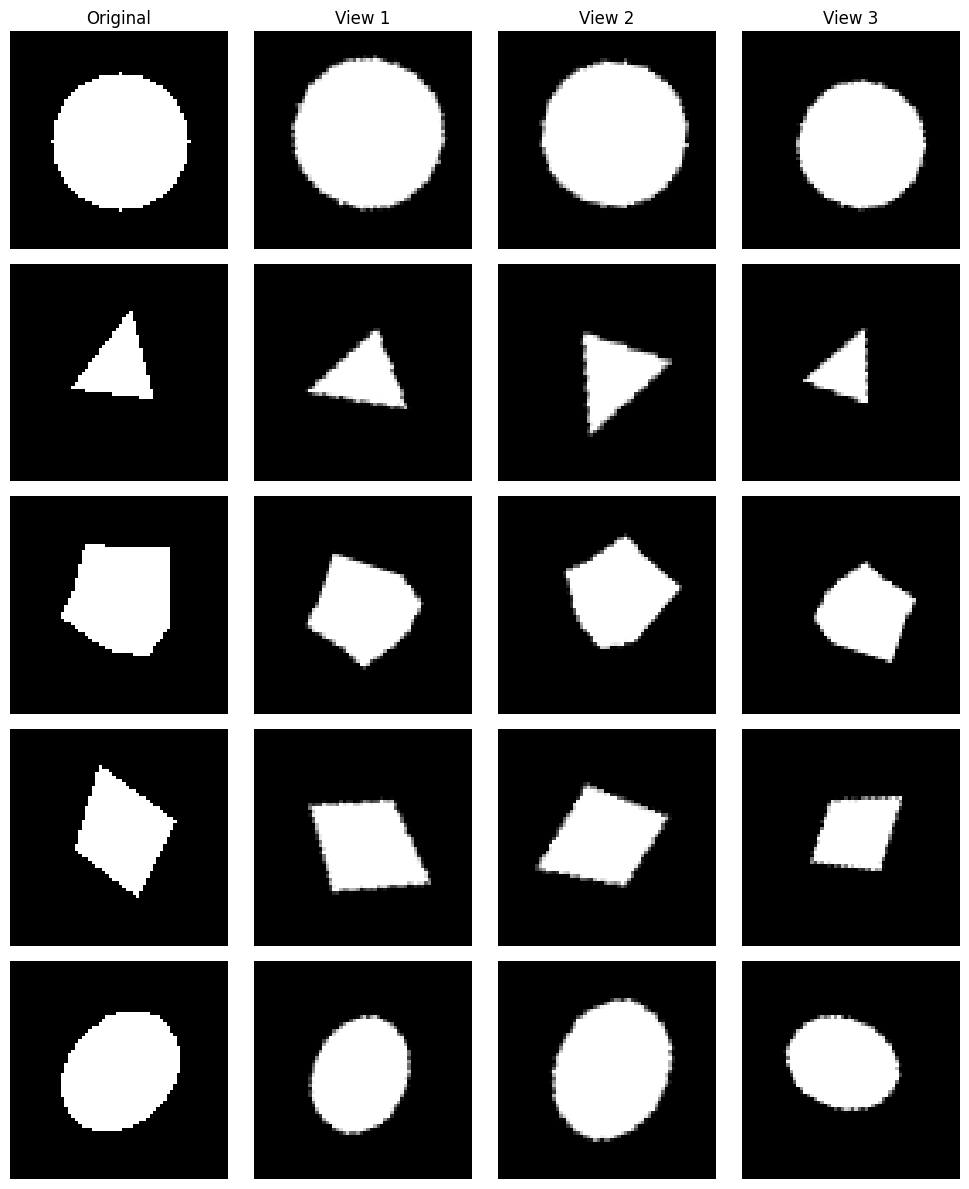

In [3]:
# Visualize generated shapes and augmentations

rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(
    5, 4,
    figsize=(10, 12)
)

for i in range(5):

    shape = generate_random_shape(
        PATCH_SIZE, rng
    )

    axes[i, 0].imshow(shape, cmap="gray")

    for j in range(1, 4):
        transformed = augment_shape(shape, rng)

        axes[i, j].imshow(
            transformed,
            cmap="gray",
            vmin=0,
            vmax=1,
        )

    for ax in axes[i]:
        ax.axis("off")

axes[0, 0].set_title("Original")
axes[0, 1].set_title("View 1")
axes[0, 2].set_title("View 2")
axes[0, 3].set_title("View 3")

plt.tight_layout()
plt.show()

## Part B: Build GeoEmbed-Tiny

The output is a unit-normalized vector:
```math
z \in \mathbb R^{64}, \|z\|_2=1
```

```math
S(A,B)=\mathbf z_A^\top\mathbf z_B
```




Higher scores indicate greater learned similarity.

In [4]:
# Lightweight neural network

class DepthwiseSeparableBlock(nn.Module):

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                stride=stride,
                padding=1,
                groups=in_channels,
                bias=False,
            ),
            nn.BatchNorm2d(in_channels),
            nn.SiLU(),

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.SiLU(),
        )

    def forward(self, x):
        return self.block(x)


class GeoEmbedTiny(nn.Module):

    def __init__(self, embedding_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(
                1, 16,
                kernel_size=3,
                stride=2,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(16),
            nn.SiLU(),

            DepthwiseSeparableBlock(16, 24, stride=2),
            DepthwiseSeparableBlock(24, 40, stride=2),
            DepthwiseSeparableBlock(40, 64, stride=2),
            DepthwiseSeparableBlock(64, 96, stride=2),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )

        self.embedding = nn.Linear(
            96, embedding_dim
        )

        self.projector = nn.Sequential(
            nn.Linear(embedding_dim, 128),
            nn.SiLU(),
            nn.Linear(128, 128),
        )

    def forward(self, x, return_projection=False):

        features = self.encoder(x)

        embedding = F.normalize(
            self.embedding(features),
            dim=1
        )

        if return_projection:
            projection = F.normalize(
                self.projector(embedding),
                dim=1
            )
            return embedding, projection

        return embedding


model = GeoEmbedTiny(
    embedding_dim=EMBEDDING_DIM
).to(device)

n_params = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Model parameters: {n_params:,}")

Model parameters: 43,296


## Part C: Train the embedding network

In [5]:
# Dataset of paired augmented shapes

class ShapePairDataset(Dataset):

    def __init__(self, n_samples=20000, seed=42):
        self.n_samples = n_samples
        self.rng = np.random.default_rng(seed)

        # Generate and retain underlying shape identities
        self.shapes = [
            generate_random_shape(
                PATCH_SIZE, self.rng
            )
            for _ in range(n_samples)
        ]

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):

        shape = self.shapes[idx]

        view1 = augment_shape(shape)
        view2 = augment_shape(shape)

        view1 = torch.from_numpy(
            view1[None, :, :]
        )

        view2 = torch.from_numpy(
            view2[None, :, :]
        )

        return view1, view2


train_dataset = ShapePairDataset(
    n_samples=20000
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
)

In [6]:
# Contrastive loss function

"""

For the first baseline, we'll use a symmetric InfoNCE loss.

This is simpler than the hybrid VICReg objective discussed earlier and gives us an easier starting point for testing the matching concept.

"""

def contrastive_loss(z1, z2, temperature=0.1):

    batch_size = z1.shape[0]

    logits = (
        z1 @ z2.T
    ) / temperature

    labels = torch.arange(
        batch_size,
        device=z1.device,
    )

    loss_forward = F.cross_entropy(
        logits, labels
    )

    loss_backward = F.cross_entropy(
        logits.T, labels
    )

    return 0.5 * (
        loss_forward + loss_backward
    )

Epoch 01/10 | Loss: 4.3782
Epoch 02/10 | Loss: 3.7006
Epoch 03/10 | Loss: 3.3743
Epoch 04/10 | Loss: 3.2516
Epoch 05/10 | Loss: 3.0007
Epoch 06/10 | Loss: 2.7686
Epoch 07/10 | Loss: 2.6232
Epoch 08/10 | Loss: 2.5119
Epoch 09/10 | Loss: 2.3724
Epoch 10/10 | Loss: 2.2946


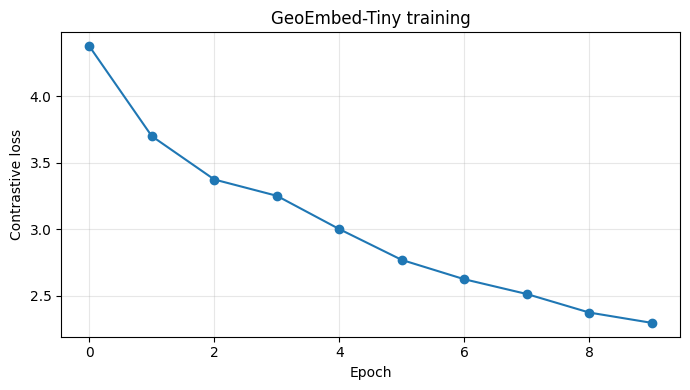

In [7]:
# Train GeoEmbed-Tiny

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

N_EPOCHS = 10

training_losses = []

for epoch in range(N_EPOCHS):

    model.train()

    epoch_loss = 0.0

    for view1, view2 in train_loader:

        view1 = view1.to(device)
        view2 = view2.to(device)

        optimizer.zero_grad()

        _, z1 = model(
            view1,
            return_projection=True,
        )

        _, z2 = model(
            view2,
            return_projection=True,
        )

        loss = contrastive_loss(z1, z2)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    epoch_loss /= len(train_loader)

    training_losses.append(epoch_loss)

    print(
        f"Epoch {epoch+1:02d}/{N_EPOCHS} "
        f"| Loss: {epoch_loss:.4f}"
    )

plt.figure(figsize=(7, 4))
plt.plot(training_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Contrastive loss")
plt.title("GeoEmbed-Tiny training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Part D: Generate two images for registration

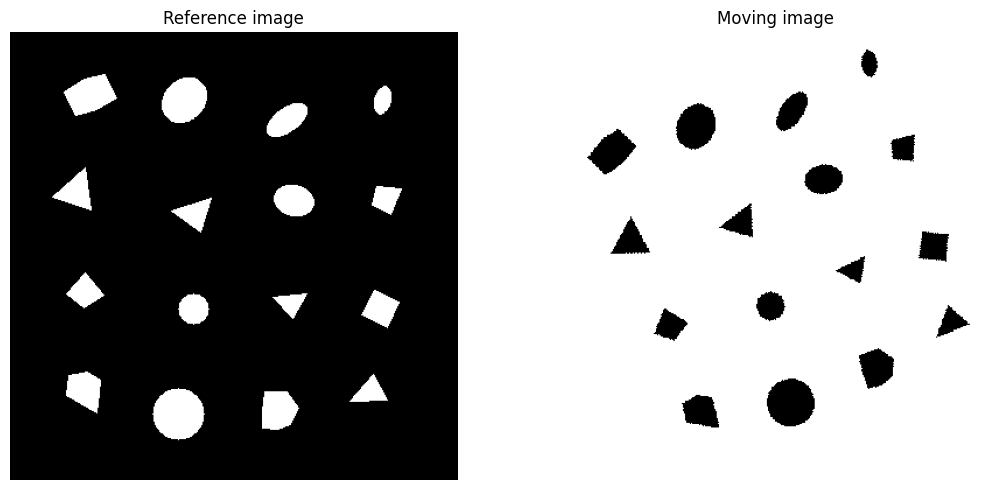

In [8]:
# Create a synthetic registration pair

def generate_registration_pair(
    image_size=384,
    grid_size=4,
    angle=20,
    scale=0.93,
    tx=12,
    ty=-8,
    seed=123,
):
    rng = np.random.default_rng(seed)

    reference = np.zeros(
        (image_size, image_size),
        dtype=np.uint8,
    )

    # Place objects on a jittered grid
    locations = np.linspace(
        65,
        image_size - 65,
        grid_size,
    )

    reference_centers = []

    for y in locations:
        for x in locations:

            cx = int(x + rng.uniform(-12, 12))
            cy = int(y + rng.uniform(-12, 12))

            shape = generate_random_shape(
                PATCH_SIZE, rng
            )

            r = PATCH_SIZE // 2

            roi = reference[
                cy-r:cy+r,
                cx-r:cx+r,
            ]

            np.maximum(
                roi, shape,
                out=roi,
            )

            reference_centers.append([cx, cy])

    reference_centers = np.asarray(
        reference_centers,
        dtype=np.float32,
    )

    # OpenCV transformation:
    # reference coordinates -> moving coordinates
    M = cv2.getRotationMatrix2D(
        (image_size/2, image_size/2),
        angle,
        scale,
    )

    M[:, 2] += [tx, ty]

    moving = cv2.warpAffine(
        reference,
        M,
        (image_size, image_size),
        flags=cv2.INTER_NEAREST,
        borderValue=0,
    )

    # Add polarity inversion to moving image
    # (the geometric masks remain separately available)
    reference_display = reference.copy()
    moving_display = 255 - moving

    return {
        "reference_mask": reference,
        "moving_mask": moving,
        "reference_image": reference_display,
        "moving_image": moving_display,
        "true_forward_transform": M,
        "reference_centers": reference_centers,
    }


pair = generate_registration_pair()

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 5)
)

axes[0].imshow(
    pair["reference_image"],
    cmap="gray"
)
axes[0].set_title("Reference image")

axes[1].imshow(
    pair["moving_image"],
    cmap="gray"
)
axes[1].set_title("Moving image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Part E: Extract objects and match embeddings

In [9]:
# Detect objects and extract patches

def extract_object_patches(
    binary_mask,
    patch_size=64,
    min_area=30,
):
    mask = (
        binary_mask > 0
    ).astype(np.uint8)

    n_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8,
        )
    )

    half = patch_size // 2

    padded = cv2.copyMakeBorder(
        mask,
        half, half, half, half,
        cv2.BORDER_CONSTANT,
        value=0,
    )

    patches = []
    centers = []

    for label_id in range(1, n_labels):

        area = stats[
            label_id,
            cv2.CC_STAT_AREA
        ]

        if area < min_area:
            continue

        cx, cy = centroids[label_id]

        # Center patch on detected object
        x = int(round(cx))
        y = int(round(cy))

        # Keep only the selected component
        component = (
            labels == label_id
        ).astype(np.uint8)

        component_padded = cv2.copyMakeBorder(
            component,
            half, half, half, half,
            cv2.BORDER_CONSTANT,
            value=0,
        )

        patch = component_padded[
            y:y+patch_size,
            x:x+patch_size,
        ]

        patches.append(
            patch.astype(np.float32)
        )

        centers.append([cx, cy])

    if not patches:
        return (
            np.empty(
                (0, patch_size, patch_size),
                dtype=np.float32
            ),
            np.empty((0, 2), dtype=np.float32),
        )

    return (
        np.stack(patches),
        np.asarray(centers, dtype=np.float32),
    )

In [10]:
# Calculate learned descriptors

@torch.no_grad()
def compute_embeddings(model, patches, device):

    if len(patches) == 0:
        return np.empty(
            (0, EMBEDDING_DIM),
            dtype=np.float32,
        )

    model.eval()

    x = torch.from_numpy(
        patches[:, None, :, :]
    ).float().to(device)

    embeddings = model(x)

    return embeddings.cpu().numpy()


ref_patches, ref_points = extract_object_patches(
    pair["reference_mask"]
)

mov_patches, mov_points = extract_object_patches(
    pair["moving_mask"]
)

ref_embeddings = compute_embeddings(
    model, ref_patches, device
)

mov_embeddings = compute_embeddings(
    model, mov_patches, device
)

print("Reference objects:", len(ref_points))
print("Moving objects:", len(mov_points))
print("Embedding shape:", ref_embeddings.shape)

Reference objects: 16
Moving objects: 16
Embedding shape: (16, 64)


In [11]:
# Match shapes using cosine similarity

def match_embeddings(
    ref_embeddings,
    mov_embeddings,
    min_similarity=0.0,
):
    if (
        len(ref_embeddings) == 0
        or len(mov_embeddings) == 0
    ):
        return np.empty((0, 3), dtype=np.float32)

    similarity = (
        ref_embeddings @ mov_embeddings.T
    )

    ref_to_mov = np.argmax(
        similarity, axis=1
    )

    mov_to_ref = np.argmax(
        similarity, axis=0
    )

    matches = []

    for i, j in enumerate(ref_to_mov):

        if mov_to_ref[j] != i:
            continue

        score = similarity[i, j]

        if score >= min_similarity:
            matches.append([
                i, j, score
            ])

    if not matches:
        return np.empty((0, 3), dtype=np.float32)

    matches = np.asarray(
        matches,
        dtype=np.float32,
    )

    return matches[
        np.argsort(matches[:, 2])[::-1]
    ]


matches = match_embeddings(
    ref_embeddings,
    mov_embeddings,
)

print("Initial matches:", len(matches))

Initial matches: 13


## Part F: Estimate image registration

In [12]:
# Robust transformation estimation

def estimate_registration(
    ref_points,
    mov_points,
    matches,
    ransac_threshold=4.0,
):

    if len(matches) < 3:
        raise ValueError(
            "At least 3 tentative matches are required."
        )

    ref_indices = matches[:, 0].astype(int)
    mov_indices = matches[:, 1].astype(int)

    dst = ref_points[ref_indices]
    src = mov_points[mov_indices]

    # Moving coordinates -> reference coordinates
    M, inliers = cv2.estimateAffinePartial2D(
        src,
        dst,
        method=cv2.RANSAC,
        ransacReprojThreshold=ransac_threshold,
        maxIters=5000,
        confidence=0.999,
        refineIters=20,
    )

    if M is None:
        raise RuntimeError(
            "RANSAC could not estimate a transformation."
        )

    inliers = inliers.ravel().astype(bool)

    transformed = cv2.transform(
        src[None, :, :],
        M
    )[0]

    errors = np.linalg.norm(
        transformed - dst,
        axis=1
    )

    return {
        "transform": M,
        "inliers": inliers,
        "errors": errors,
        "rmse_inliers": np.sqrt(
            np.mean(errors[inliers]**2)
        ),
    }


registration = estimate_registration(
    ref_points,
    mov_points,
    matches,
)

print("Estimated moving-to-reference transform:")
print(registration["transform"])

print(
    "RANSAC inliers:",
    registration["inliers"].sum(),
    "/", len(matches)
)

print(
    "Inlier RMSE:",
    registration["rmse_inliers"],
    "pixels"
)

Estimated moving-to-reference transform:
[[  1.01042945  -0.36787153  53.55681999]
 [  0.36787153   1.01042945 -68.97680952]]
RANSAC inliers: 10 / 13
Inlier RMSE: 0.041933533 pixels


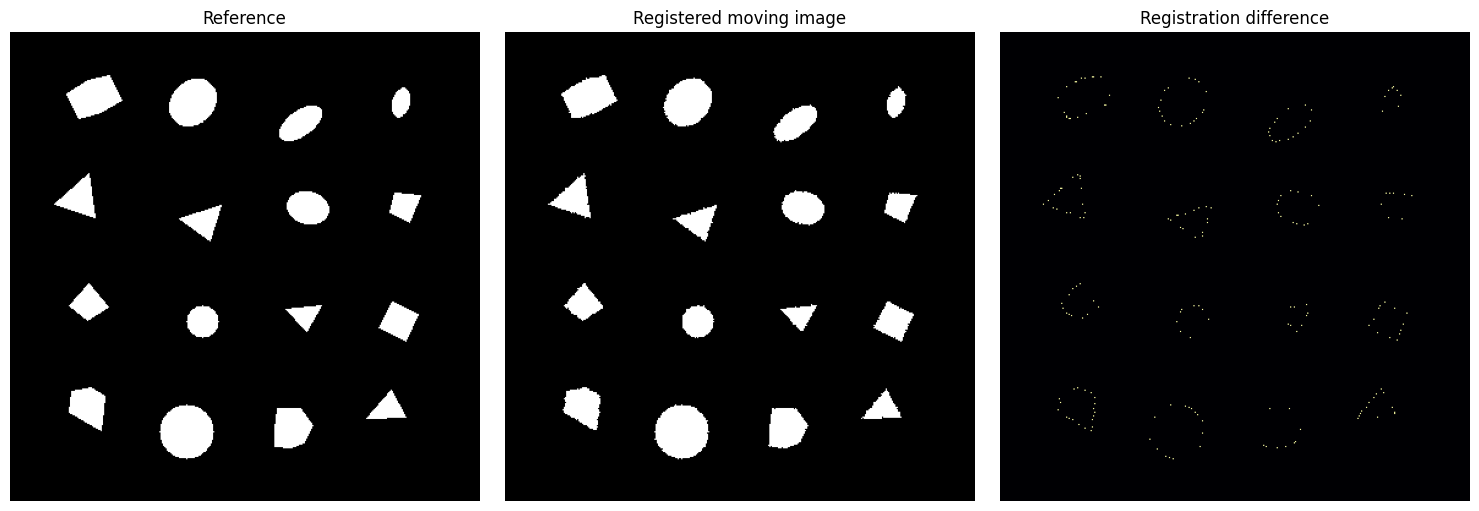

In [13]:
# Warp and visualize

M_est = registration["transform"]

h, w = pair["reference_mask"].shape

aligned = cv2.warpAffine(
    pair["moving_mask"],
    M_est,
    (w, h),
    flags=cv2.INTER_NEAREST,
)

reference = pair["reference_mask"]

difference = cv2.absdiff(
    reference, aligned
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(reference, cmap="gray")
axes[0].set_title("Reference")

axes[1].imshow(aligned, cmap="gray")
axes[1].set_title("Registered moving image")

axes[2].imshow(difference, cmap="inferno")
axes[2].set_title("Registration difference")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Compare with ground truth

'''
We should not rely only on inlier RMSE, because RANSAC can occasionally find a geometrically consistent but incorrect configuration.

Instead, compare the predicted transformation against the true transformation across the image.

'''

# True transform is reference -> moving
M_true_forward = pair["true_forward_transform"]

# Invert to get moving -> reference
M_true_inverse = cv2.invertAffineTransform(
    M_true_forward
)

# Reference points transformed into moving coordinates
true_moving_points = cv2.transform(
    pair["reference_centers"][None, :, :],
    M_true_forward
)[0]

# Recover those coordinates with estimated registration
recovered_reference_points = cv2.transform(
    true_moving_points[None, :, :],
    M_est
)[0]

errors = np.linalg.norm(
    recovered_reference_points
    - pair["reference_centers"],
    axis=1
)

ground_truth_rmse = np.sqrt(
    np.mean(errors**2)
)

print("True inverse transform:")
print(M_true_inverse)

print("\nEstimated inverse transform:")
print(M_est)

print(
    f"\nGround-truth registration RMSE: "
    f"{ground_truth_rmse:.3f} pixels"
)

print(
    f"Maximum landmark error: "
    f"{errors.max():.3f} pixels"
)

True inverse transform:
[[  1.01042217  -0.36776359  53.54237821]
 [  0.36776359   1.01042217 -68.94145319]]

Estimated inverse transform:
[[  1.01042945  -0.36787153  53.55681999]
 [  0.36787153   1.01042945 -68.97680952]]

Ground-truth registration RMSE: 0.018 pixels
Maximum landmark error: 0.029 pixels


## Part G: Visualize the predicted correspondences

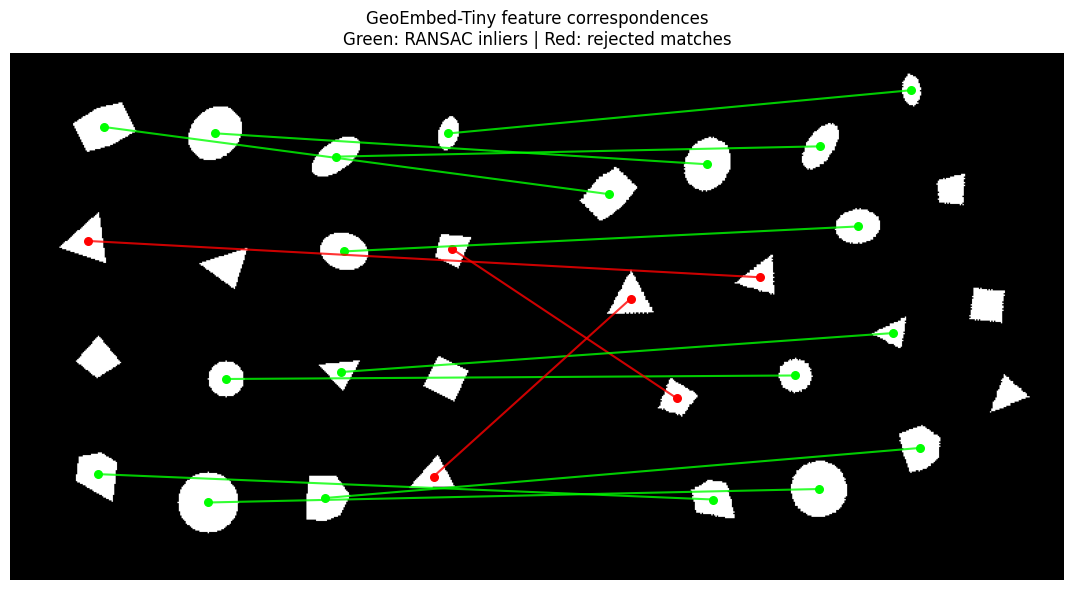

In [15]:
# Draw matching landmarks between images
# This is one of the most important visualizations for evaluating whether our system works.

def plot_feature_matches(
    reference,
    moving,
    ref_points,
    mov_points,
    matches,
    inliers=None,
):
    h1, w1 = reference.shape
    h2, w2 = moving.shape

    fig, ax = plt.subplots(figsize=(13, 6))

    canvas = np.concatenate(
        [reference, moving],
        axis=1
    )

    ax.imshow(canvas, cmap="gray")

    for k, (i, j, score) in enumerate(matches):

        i, j = int(i), int(j)

        x1, y1 = ref_points[i]
        x2, y2 = mov_points[j]

        x2 += w1

        correct = (
            inliers is None
            or inliers[k]
        )

        color = "lime" if correct else "red"

        ax.plot(
            [x1, x2],
            [y1, y2],
            color=color,
            linewidth=1.5,
            alpha=0.8,
        )

        ax.scatter(
            [x1, x2],
            [y1, y2],
            s=30,
            color=color,
        )

    ax.set_title(
        "GeoEmbed-Tiny feature correspondences\n"
        "Green: RANSAC inliers | Red: rejected matches"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_feature_matches(
    pair["reference_mask"],
    pair["moving_mask"],
    ref_points,
    mov_points,
    matches,
    registration["inliers"],
)

In [16]:
# Evaluate matches against ground truth
'''
This lets us compare:
    - Neural-network matching before RANSAC.
    - Matches accepted after RANSAC.
    - The number of detected reference and moving objects.
    - The number of missed or incorrect matches.
'''


def evaluate_matches_ground_truth(
    ref_points,
    mov_points,
    matches,
    true_forward_transform,
    ransac_inliers=None,
    tolerance=3.0,
):
    """
    Evaluate predicted correspondences using the
    known reference-to-moving transformation.
    """

    if len(matches) == 0:
        print("No matches available.")
        return None

    ref_idx = matches[:, 0].astype(int)
    mov_idx = matches[:, 1].astype(int)

    # Transform reference points into moving coordinates
    predicted_moving = cv2.transform(
        ref_points[ref_idx][None, :, :],
        true_forward_transform
    )[0]

    actual_moving = mov_points[mov_idx]

    errors = np.linalg.norm(
        predicted_moving - actual_moving,
        axis=1
    )

    correct = errors <= tolerance

    print("=== Descriptor Matching ===")
    print(f"Total matches: {len(matches)}")
    print(f"Correct matches: {correct.sum()}")
    print(f"Incorrect matches: {(~correct).sum()}")
    print(f"Precision: {correct.mean():.3f}")

    if ransac_inliers is not None:

        inliers = np.asarray(
            ransac_inliers,
            dtype=bool
        )

        accepted_correct = correct[inliers]

        print("\n=== After RANSAC ===")
        print(f"Accepted matches: {inliers.sum()}")
        print(f"Correct accepted: {accepted_correct.sum()}")
        print(
            f"Incorrect accepted: "
            f"{(~accepted_correct).sum()}"
        )

        if inliers.sum() > 0:
            print(
                f"Precision: "
                f"{accepted_correct.mean():.3f}"
            )

    return {
        "errors": errors,
        "correct": correct,
    }


match_evaluation = evaluate_matches_ground_truth(
    ref_points,
    mov_points,
    matches,
    pair["true_forward_transform"],
    ransac_inliers=registration["inliers"],
)

=== Descriptor Matching ===
Total matches: 13
Correct matches: 10
Incorrect matches: 3
Precision: 0.769

=== After RANSAC ===
Accepted matches: 10
Correct accepted: 10
Incorrect accepted: 0
Precision: 1.000


## Experiment 2: Geometry-Aware Feature Matching

In [ ]:
'''

Method B adds two levels of spatial reasoning.

Stage 1 — Local neighborhood matching

Compare not only shape embeddings, but also the distances to surrounding objects.




Stage 2 — Pairwise geometric consistency

Give candidate correspondences higher scores when they agree with other candidate correspondences.




Stage 3 — RANSAC registration

Use the strongest proposed correspondences to estimate the moving-to-reference transformation.


'''

In [17]:
# Compute local spatial descriptors

from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment


def compute_spatial_descriptors(points, k=5):
    """
    Compute local spatial descriptors for detected features.

    Parameters
    ----------
    points : ndarray, shape (N, 2)
        Feature center coordinates.
    k : int
        Number of nearest neighbors to describe.

    Returns
    -------
    descriptors : ndarray, shape (N, k)
        Normalized nearest-neighbor distance signatures.
    spacing : float
        Median nearest-neighbor distance.
    """

    points = np.asarray(points, dtype=np.float64)

    n = len(points)

    if n < 2:
        raise ValueError(
            "At least two objects are required."
        )

    # Pairwise Euclidean distances
    D = cdist(points, points)

    # Ignore self-distances
    np.fill_diagonal(D, np.inf)

    # Sort distances to neighboring objects
    sorted_distances = np.sort(D, axis=1)

    # Median nearest-neighbor spacing
    spacing = np.median(sorted_distances[:, 0])

    if spacing <= 0:
        raise ValueError(
            "Duplicate or degenerate feature coordinates."
        )

    # Normalize to reduce sensitivity to global scaling
    normalized = sorted_distances / spacing

    # Keep k nearest neighbors
    k_effective = min(k, n - 1)

    descriptors = normalized[:, :k_effective]

    # Pad when there are fewer than k neighbors
    if k_effective < k:
        descriptors = np.pad(
            descriptors,
            ((0, 0), (0, k - k_effective)),
            mode="edge",
        )

    return descriptors, spacing


# Reference image
ref_spatial, ref_spacing = compute_spatial_descriptors(
    ref_points,
    k=5,
)

# Moving image
mov_spatial, mov_spacing = compute_spatial_descriptors(
    mov_points,
    k=5,
)

print("Reference spatial descriptors:", ref_spatial.shape)
print("Moving spatial descriptors:", mov_spatial.shape)

print("Reference spacing:", ref_spacing)
print("Moving spacing:", mov_spacing)

print(
    "Estimated moving-to-reference scale:",
    ref_spacing / mov_spacing,
)

Reference spatial descriptors: (16, 5)
Moving spatial descriptors: (16, 5)
Reference spacing: 80.90649723072774
Moving spacing: 75.28465020519573
Estimated moving-to-reference scale: 1.074674545345022


In [18]:
# Combine shape and local spatial similarity

def compute_combined_similarity(
    ref_embeddings,
    mov_embeddings,
    ref_spatial,
    mov_spatial,
    shape_weight=0.7,
    spatial_sigma=0.5,
):
    """
    Combine neural shape similarity and local
    spatial-neighborhood similarity.
    """

    # Neural descriptor similarity
    shape_similarity = (
        ref_embeddings @ mov_embeddings.T
    )

    # Map cosine similarity from [-1, 1] to [0, 1]
    shape_similarity = np.clip(
        (shape_similarity + 1) / 2,
        0,
        1,
    )

    # Compare spatial descriptor vectors
    spatial_distances = cdist(
        ref_spatial,
        mov_spatial,
    )

    spatial_similarity = np.exp(
        -0.5 * (
            spatial_distances / spatial_sigma
        ) ** 2
    )

    # Weighted combination
    combined = (
        shape_weight * shape_similarity
        + (1 - shape_weight) * spatial_similarity
    )

    return {
        "shape": shape_similarity,
        "spatial": spatial_similarity,
        "combined": combined,
    }


similarities = compute_combined_similarity(
    ref_embeddings,
    mov_embeddings,
    ref_spatial,
    mov_spatial,
    shape_weight=0.7,
    spatial_sigma=0.5,
)

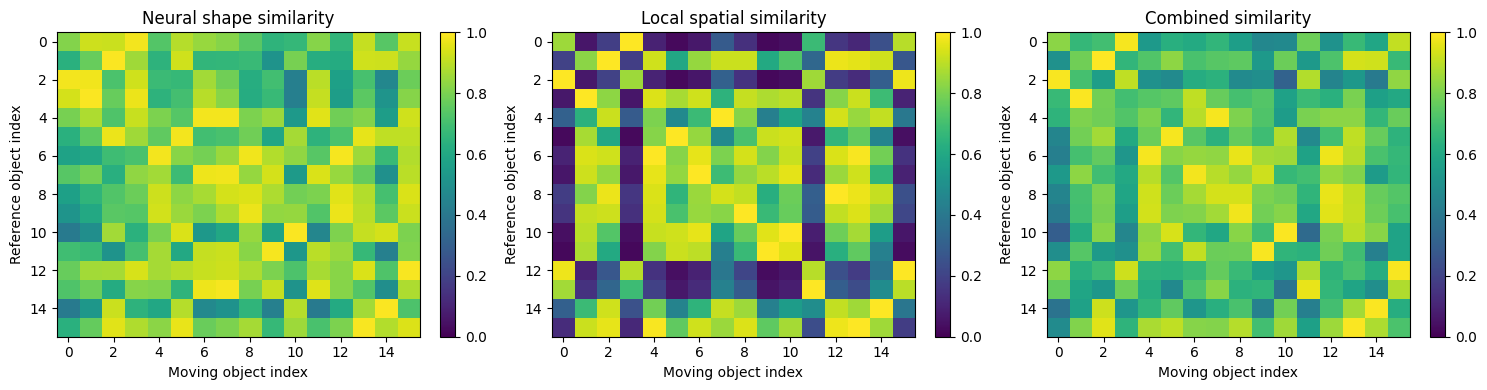

In [19]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
)

titles = [
    "Neural shape similarity",
    "Local spatial similarity",
    "Combined similarity",
]

keys = ["shape", "spatial", "combined"]

for ax, key, title in zip(axes, keys, titles):

    im = ax.imshow(
        similarities[key],
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="auto",
    )

    ax.set_title(title)
    ax.set_xlabel("Moving object index")
    ax.set_ylabel("Reference object index")

    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

In [20]:
# Build a correspondence compatibility graph

def build_correspondence_graph(
    ref_points,
    mov_points,
    similarity,
    scale_estimate,
    top_k=5,
    distance_sigma=0.10,
    min_separation=8.0,
):
    """
    Construct candidate correspondences and their
    pairwise geometric compatibility matrix.

    The compatibility is based on relative distances
    under a similarity transformation.
    """

    n_ref, n_mov = similarity.shape

    if n_ref == 0 or n_mov == 0:
        raise ValueError("No features available.")

    if scale_estimate <= 0:
        raise ValueError("Scale estimate must be positive.")

    # Candidate matches: top-k moving objects
    # for each reference object
    candidates = []

    for i in range(n_ref):

        candidate_ids = np.argsort(
            similarity[i]
        )[-min(top_k, n_mov):]

        for j in candidate_ids:
            candidates.append((i, j))

    candidates = np.asarray(candidates, dtype=int)

    ref_idx = candidates[:, 0]
    mov_idx = candidates[:, 1]

    unary_scores = similarity[ref_idx, mov_idx]

    # Distances between reference endpoints
    d_ref = cdist(
        ref_points[ref_idx],
        ref_points[ref_idx],
    )

    # Distances between moving endpoints
    d_mov = cdist(
        mov_points[mov_idx],
        mov_points[mov_idx],
    )

    # Candidate pairs cannot reuse the same object
    valid = (
        (ref_idx[:, None] != ref_idx[None, :])
        &
        (mov_idx[:, None] != mov_idx[None, :])
    )

    # Avoid unstable very-short-baseline comparisons
    valid &= (
        (d_ref >= min_separation)
        &
        (d_mov * scale_estimate >= min_separation)
    )

    # Log scale ratio: symmetric for scale deviations
    ratio = d_ref / np.maximum(
        scale_estimate * d_mov,
        1e-8,
    )

    log_ratio = np.log(
        np.maximum(ratio, 1e-8)
    )

    compatibility = np.exp(
        -0.5 * (
            log_ratio / distance_sigma
        ) ** 2
    )

    compatibility *= valid

    np.fill_diagonal(compatibility, 0)

    return candidates, unary_scores, compatibility


scale_estimate = ref_spacing / mov_spacing

candidates, unary_scores, compatibility = (
    build_correspondence_graph(
        ref_points,
        mov_points,
        similarities["combined"],
        scale_estimate=scale_estimate,
        top_k=5,
        distance_sigma=0.10,
    )
)

print("Candidate correspondences:", len(candidates))
print("Compatibility matrix:", compatibility.shape)

Candidate correspondences: 80
Compatibility matrix: (80, 80)


In [21]:
# Spatial consensus and one-to-one matching

def spatial_consensus_matching(
    candidates,
    unary_scores,
    compatibility,
    n_ref,
    n_mov,
    n_iterations=10,
    unary_weight=0.45,
    min_score=0.35,
):
    """
    Iteratively combine individual matching confidence
    with support from geometrically compatible matches.

    Uses a one-to-one linear assignment at the end.
    """

    ref_idx = candidates[:, 0]
    mov_idx = candidates[:, 1]

    unary = np.clip(
        np.asarray(unary_scores, dtype=float),
        0, 1,
    )

    # Initialize with individual-match confidence
    scores = unary.copy()

    for _ in range(n_iterations):

        # Normalize scores for each reference feature
        weights = np.zeros_like(scores)

        for i in np.unique(ref_idx):

            mask = ref_idx == i
            values = scores[mask]

            # Normalized soft assignment
            exp_values = np.exp(
                8.0 * (values - values.max())
            )

            weights[mask] = (
                exp_values / exp_values.sum()
            )

        # Geometric support from other candidates
        support = compatibility @ weights

        # Normalize support into [0, 1]
        if support.max() > support.min():
            support = (
                support - support.min()
            ) / (
                support.max() - support.min()
            )
        else:
            support = np.zeros_like(support)

        # Combine shape/neighborhood evidence
        # with global geometric agreement
        scores = (
            unary_weight * unary
            + (1 - unary_weight) * support
        )

    # Build assignment score matrix
    assignment_scores = np.zeros(
        (n_ref, n_mov),
        dtype=float,
    )

    assignment_scores[ref_idx, mov_idx] = scores

    # Add dummy columns to allow unmatched objects
    extended = np.full(
        (n_ref, n_mov + n_ref),
        min_score,
        dtype=float,
    )

    extended[:, :n_mov] = assignment_scores

    # Maximize total assignment score
    row_ind, col_ind = linear_sum_assignment(
        -extended
    )

    matches = []

    for i, j in zip(row_ind, col_ind):

        if j >= n_mov:
            continue

        score = assignment_scores[i, j]

        if score > min_score:
            matches.append([i, j, score])

    matches = np.asarray(
        matches,
        dtype=np.float32,
    ).reshape(-1, 3)

    if len(matches):
        matches = matches[
            np.argsort(matches[:, 2])[::-1]
        ]

    return matches, scores


matches_B, graph_scores = spatial_consensus_matching(
    candidates,
    unary_scores,
    compatibility,
    n_ref=len(ref_points),
    n_mov=len(mov_points),
)

print("Method B proposed matches:", len(matches_B))

Method B proposed matches: 16


In [22]:
# Estimate the transformation with Method B

registration_B = None

if len(matches_B) >= 3:

    try:
        registration_B = estimate_registration(
            ref_points,
            mov_points,
            matches_B,
            ransac_threshold=4.0,
        )

        print("Method B transformation:")
        print(registration_B["transform"])

        print(
            "\nRANSAC inliers:",
            registration_B["inliers"].sum(),
            "/", len(matches_B)
        )

        print(
            "Inlier RMSE:",
            registration_B["rmse_inliers"],
            "pixels"
        )

    except (ValueError, RuntimeError) as exc:
        print("Method B registration failed:", exc)

else:
    print("Insufficient matches for Method B registration.")

Method B transformation:
[[  1.01034171  -0.36790653  53.57812179]
 [  0.36790653   1.01034171 -68.97277755]]

RANSAC inliers: 16 / 16
Inlier RMSE: 0.053761747 pixels


In [23]:
# Compare Method A and Method B quantitatively

def evaluate_method(
    name,
    matches,
    registration_result,
    ref_points,
    mov_points,
    true_forward_transform,
    true_reference_centers,
):
    """
    Evaluate descriptor matching, RANSAC verification,
    and actual registration error.
    """

    if registration_result is None:
        print(f"{name}: Registration unavailable")
        return None

    evaluation = evaluate_matches_ground_truth(
        ref_points,
        mov_points,
        matches,
        true_forward_transform,
        ransac_inliers=registration_result["inliers"],
        tolerance=3.0,
    )

    M_est = registration_result["transform"]

    # Transform original reference landmarks into
    # the moving image, using the known transform
    true_moving_centers = cv2.transform(
        true_reference_centers[None, :, :],
        true_forward_transform,
    )[0]

    # Recover reference coordinates
    recovered = cv2.transform(
        true_moving_centers[None, :, :],
        M_est,
    )[0]

    landmark_errors = np.linalg.norm(
        recovered - true_reference_centers,
        axis=1,
    )

    rmse = np.sqrt(
        np.mean(landmark_errors**2)
    )

    print(f"\n{name}")
    print("-" * 45)
    print(f"Ground-truth RMSE: {rmse:.4f} px")
    print(f"Maximum error: {landmark_errors.max():.4f} px")

    return {
        "method": name,
        "rmse": rmse,
        "max_error": landmark_errors.max(),
        "n_matches": len(matches),
        "n_inliers": int(
            registration_result["inliers"].sum()
        ),
        "precision": (
            evaluation["correct"].mean()
            if evaluation is not None
            else np.nan
        ),
    }


results_A = evaluate_method(
    "Method A — Embedding only",
    matches,
    registration,
    ref_points,
    mov_points,
    pair["true_forward_transform"],
    pair["reference_centers"],
)

results_B = evaluate_method(
    "Method B — Spatial context",
    matches_B,
    registration_B,
    ref_points,
    mov_points,
    pair["true_forward_transform"],
    pair["reference_centers"],
)

=== Descriptor Matching ===
Total matches: 13
Correct matches: 10
Incorrect matches: 3
Precision: 0.769

=== After RANSAC ===
Accepted matches: 10
Correct accepted: 10
Incorrect accepted: 0
Precision: 1.000

Method A — Embedding only
---------------------------------------------
Ground-truth RMSE: 0.0185 px
Maximum error: 0.0292 px
=== Descriptor Matching ===
Total matches: 16
Correct matches: 16
Incorrect matches: 0
Precision: 1.000

=== After RANSAC ===
Accepted matches: 16
Correct accepted: 16
Incorrect accepted: 0
Precision: 1.000

Method B — Spatial context
---------------------------------------------
Ground-truth RMSE: 0.0274 px
Maximum error: 0.0443 px


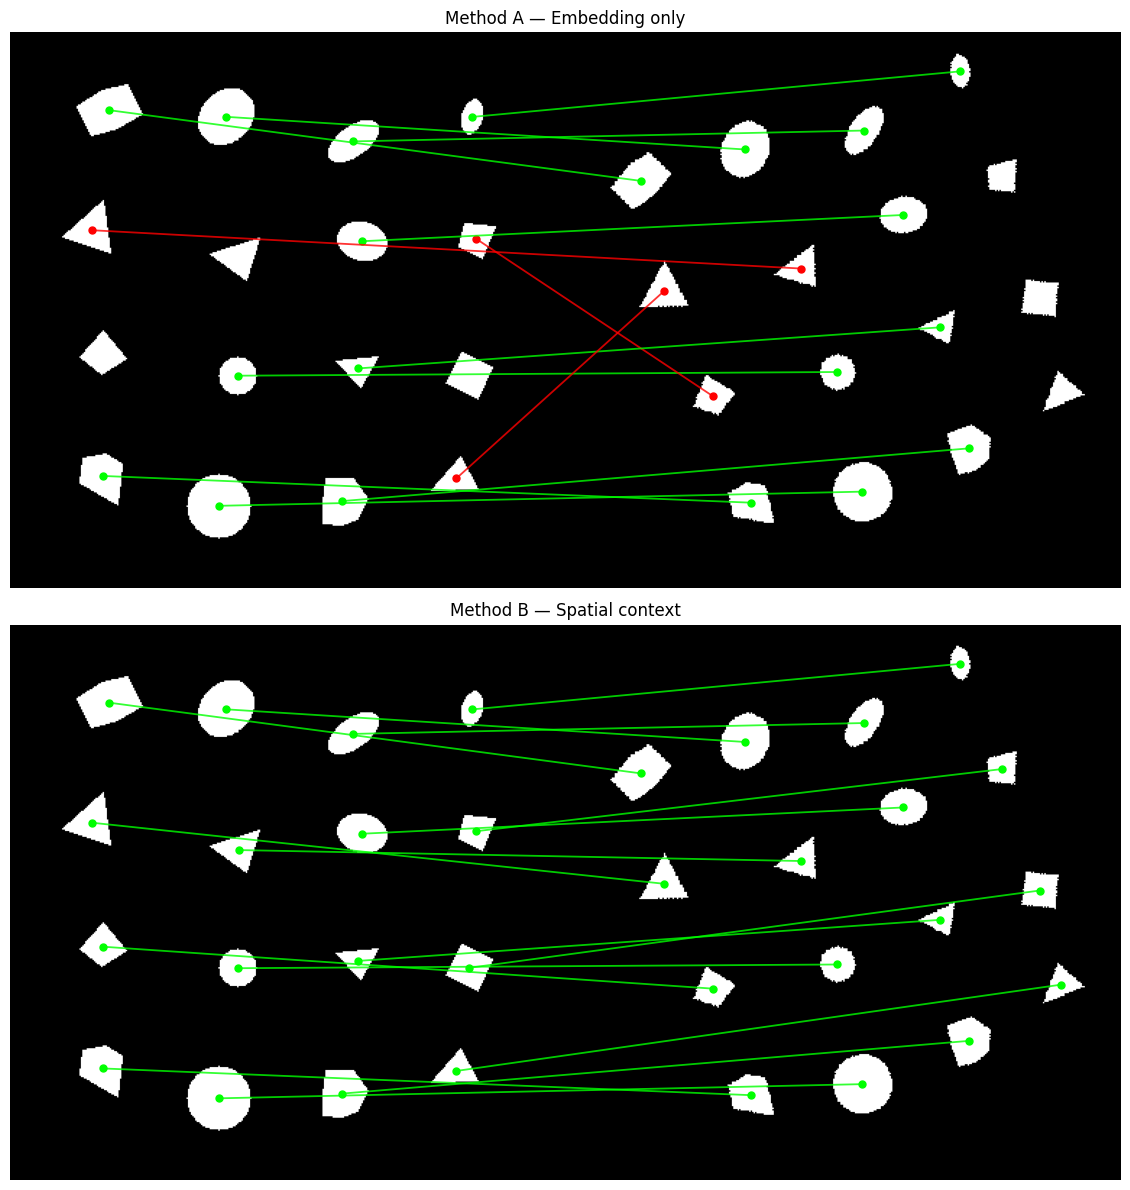

In [24]:
# Visualize the correspondences side by side

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 12),
)

methods = [
    ("Method A — Embedding only", matches, registration),
    ("Method B — Spatial context", matches_B, registration_B),
]

for ax, (title, current_matches, current_reg) in zip(
    axes, methods
):
    h, w = pair["reference_mask"].shape

    canvas = np.concatenate(
        [
            pair["reference_mask"],
            pair["moving_mask"],
        ],
        axis=1,
    )

    ax.imshow(canvas, cmap="gray")

    if current_reg is not None:
        inliers = current_reg["inliers"]

        for idx, (i, j, score) in enumerate(current_matches):

            i, j = int(i), int(j)

            x1, y1 = ref_points[i]
            x2, y2 = mov_points[j]

            color = (
                "lime"
                if inliers[idx]
                else "red"
            )

            ax.plot(
                [x1, x2 + w],
                [y1, y2],
                color=color,
                linewidth=1.3,
                alpha=0.8,
            )

            ax.scatter(
                [x1, x2 + w],
                [y1, y2],
                color=color,
                s=25,
            )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [25]:
import pandas as pd

comparison = pd.DataFrame([
    r for r in [results_A, results_B]
    if r is not None
])

display(comparison.round(4))

,method,rmse,max_error,n_matches,n_inliers,precision
0,Method A — Embedding only,0.0185,0.0292,13,10,0.7692
1,Method B — Spatial context,0.0274,0.0443,16,16,1.0000


In [26]:
# Benchmark over multiple image pairs
'''
This is the experiment that will really tell us whether Method B improves registration.

We'll generate 30 independent synthetic registration problems, with varying rotations,
scales, and translations, then run both methods against the same images.
'''


def benchmark_methods(model, n_trials=30, seed=2026):

    rng = np.random.default_rng(seed)
    records = []

    model.eval()

    for trial in range(n_trials):

        angle = float(rng.uniform(-90, 90))
        scale = float(rng.uniform(0.85, 1.15))
        tx, ty = rng.uniform(-20, 20, size=2)

        test_pair = generate_registration_pair(
            angle=angle,
            scale=scale,
            tx=tx,
            ty=ty,
            seed=seed + trial,
        )

        rp, rc = extract_object_patches(
            test_pair["reference_mask"]
        )
        mp, mc = extract_object_patches(
            test_pair["moving_mask"]
        )

        if min(len(rc), len(mc)) < 3:
            continue

        re = compute_embeddings(model, rp, device)
        me = compute_embeddings(model, mp, device)

        # Method A
        matches_A_trial = match_embeddings(re, me)

        # Method B
        rs, ref_spacing_trial = compute_spatial_descriptors(rc)
        ms, mov_spacing_trial = compute_spatial_descriptors(mc)

        sim = compute_combined_similarity(
            re, me, rs, ms
        )

        cand, unary, compat = build_correspondence_graph(
            rc,
            mc,
            sim["combined"],
            scale_estimate=ref_spacing_trial / mov_spacing_trial,
        )

        matches_B_trial, _ = spatial_consensus_matching(
            cand,
            unary,
            compat,
            n_ref=len(rc),
            n_mov=len(mc),
        )

        for method_name, current_matches in [
            ("A", matches_A_trial),
            ("B", matches_B_trial),
        ]:

            success = False
            rmse = np.nan
            precision = np.nan
            n_inliers = 0

            if len(current_matches):
                ri = current_matches[:, 0].astype(int)
                mi = current_matches[:, 1].astype(int)

                predicted_moving = cv2.transform(
                    rc[ri][None, :, :],
                    test_pair["true_forward_transform"],
                )[0]

                matching_errors = np.linalg.norm(
                    predicted_moving - mc[mi],
                    axis=1,
                )

                precision = np.mean(matching_errors < 3.0)

            if len(current_matches) >= 3:

                try:
                    reg = estimate_registration(
                        rc,
                        mc,
                        current_matches,
                    )

                    n_inliers = int(reg["inliers"].sum())

                    true_centers = test_pair["reference_centers"]

                    moving_centers = cv2.transform(
                        true_centers[None, :, :],
                        test_pair["true_forward_transform"],
                    )[0]

                    recovered = cv2.transform(
                        moving_centers[None, :, :],
                        reg["transform"],
                    )[0]

                    rmse = np.sqrt(
                        np.mean(
                            np.sum(
                                (recovered - true_centers)**2,
                                axis=1,
                            )
                        )
                    )

                    success = rmse < 3.0

                except (ValueError, RuntimeError, cv2.error):
                    pass

            records.append({
                "trial": trial,
                "method": method_name,
                "n_matches": len(current_matches),
                "n_inliers": n_inliers,
                "precision": precision,
                "rmse": rmse,
                "success": success,
            })

    return pd.DataFrame(records)


benchmark_df = benchmark_methods(
    model,
    n_trials=30,
)

summary = benchmark_df.groupby("method").agg(
    success_rate=("success", "mean"),
    mean_precision=("precision", "mean"),
    median_rmse=("rmse", "median"),
    mean_matches=("n_matches", "mean"),
    mean_inliers=("n_inliers", "mean"),
)

display(summary.round(4))

,success_rate,mean_precision,median_rmse,mean_matches,mean_inliers
method,,,,,
A,0.9667,0.6801,0.0314,10.9000,7.8667
B,1.0000,0.9572,0.0251,15.6667,15.2000


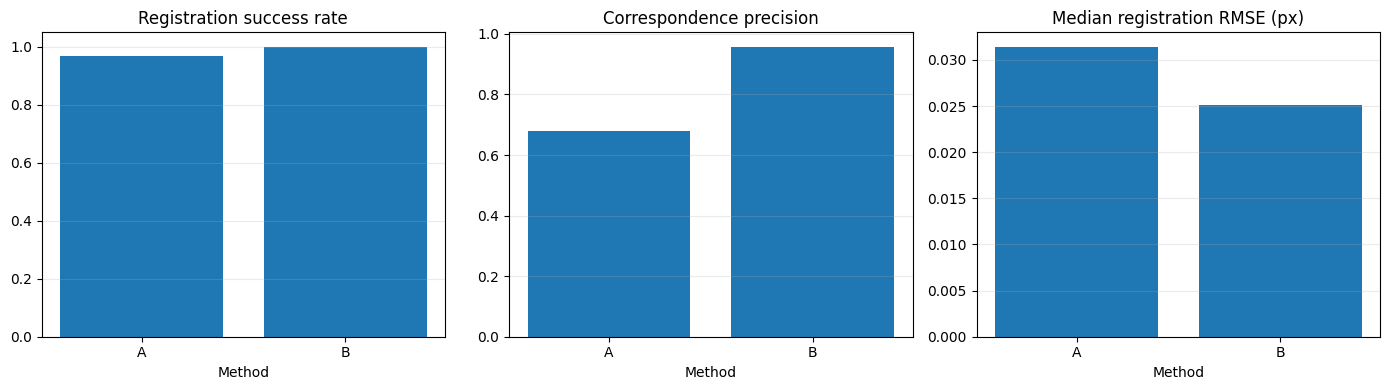

In [27]:
# Visualize benchmark results

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

metrics = [
    ("success_rate", "Registration success rate"),
    ("mean_precision", "Correspondence precision"),
    ("median_rmse", "Median registration RMSE (px)"),
]

for ax, (column, title) in zip(axes, metrics):
    ax.bar(
        summary.index,
        summary[column],
    )
    ax.set_title(title)
    ax.set_xlabel("Method")
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## Part H: Generate challenging image pairs

In [28]:
# Create a generator with object identity tracking

import time
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt


def mask_centroid(mask):
    """Calculate centroid from a binary mask."""

    moments = cv2.moments(
        mask.astype(np.uint8),
        binaryImage=True
    )

    if moments["m00"] == 0:
        return None

    return np.array([
        moments["m10"] / moments["m00"],
        moments["m01"] / moments["m00"]
    ], dtype=np.float32)


def centered_mask_patch(mask, size=64):
    """
    Extract a centered patch of one object.

    Zero padding allows objects near image boundaries.
    """

    center = mask_centroid(mask)

    if center is None:
        return None

    h, w = mask.shape
    half = size // 2

    x = int(round(center[0]))
    y = int(round(center[1]))

    padded = cv2.copyMakeBorder(
        mask.astype(np.uint8),
        half, half, half, half,
        cv2.BORDER_CONSTANT,
        value=0
    )

    patch = padded[
        y:y + size,
        x:x + size
    ]

    return patch.astype(np.float32)


def make_challenging_pair(
    image_size=384,
    grid_size=4,
    missing_fraction=0.0,
    extra_fraction=0.0,
    overlap_fraction=1.0,
    angle=20,
    scale=0.93,
    tx=12,
    ty=-8,
    seed=123,
):
    """
    Generate reference and moving images containing
    corresponding and non-corresponding objects.

    Object IDs are retained for exact matching evaluation.

    overlap_fraction controls the visible horizontal
    fraction of the moving image.
    """

    rng = np.random.default_rng(seed)

    H = W = image_size
    patch_size = PATCH_SIZE

    # Forward: reference -> moving
    M = cv2.getRotationMatrix2D(
        (W / 2, H / 2),
        angle,
        scale
    ).astype(np.float64)

    M[:, 2] += [tx, ty]

    # Moving image field-of-view mask
    visibility = np.zeros((H, W), dtype=np.uint8)

    visible_width = int(
        round(W * overlap_fraction)
    )

    visibility[:, :visible_width] = 1

    # Locations of underlying objects
    positions = np.linspace(
        65,
        image_size - 65,
        grid_size
    )

    reference_objects = []
    moving_objects = []

    object_id = 0

    for cy0 in positions:
        for cx0 in positions:

            cx = int(cx0 + rng.uniform(-6, 6))
            cy = int(cy0 + rng.uniform(-6, 6))

            shape = generate_random_shape(
                patch_size,
                rng
            )

            # Place shape in full reference image
            placement = np.array([
                [1, 0, cx - patch_size // 2],
                [0, 1, cy - patch_size // 2]
            ], dtype=np.float32)

            reference_mask = cv2.warpAffine(
                shape,
                placement,
                (W, H),
                flags=cv2.INTER_NEAREST
            )

            # Same physical object in moving coordinates
            moving_full = cv2.warpAffine(
                reference_mask,
                M,
                (W, H),
                flags=cv2.INTER_NEAREST
            )

            # Apply field-of-view restriction
            moving_mask = (
                moving_full * visibility
            ).astype(np.uint8)

            # Independent visibility in each modality
            keep_ref = rng.random() >= missing_fraction
            keep_mov = rng.random() >= missing_fraction

            if keep_ref and reference_mask.any():

                reference_objects.append({
                    "id": object_id,
                    "mask": reference_mask
                })

            # Reject severely truncated objects
            original_area = np.count_nonzero(reference_mask)
            moving_area = np.count_nonzero(moving_mask)

            visible_ratio = (
                moving_area / max(original_area, 1)
            )

            if (
                keep_mov
                and moving_area > 30
                and visible_ratio >= 0.65
            ):
                moving_objects.append({
                    "id": object_id,
                    "mask": moving_mask
                })

            object_id += 1

    # Add distractors only to moving image
    n_extra = int(round(
        grid_size**2 * extra_fraction
    ))

    occupancy = np.zeros((H, W), dtype=np.uint8)

    for obj in moving_objects:
        occupancy = cv2.bitwise_or(
            occupancy,
            obj["mask"]
        )

    for k in range(n_extra):

        for attempt in range(100):

            shape = generate_random_shape(
                patch_size,
                rng
            )

            cx = int(rng.integers(
                35,
                max(36, visible_width - 35)
            ))

            cy = int(rng.integers(35, H - 35))

            placement = np.array([
                [1, 0, cx - patch_size // 2],
                [0, 1, cy - patch_size // 2]
            ], dtype=np.float32)

            candidate = cv2.warpAffine(
                shape,
                placement,
                (W, H),
                flags=cv2.INTER_NEAREST
            )

            candidate = (
                candidate * visibility
            ).astype(np.uint8)

            # Avoid intersection with existing shapes
            expanded = cv2.dilate(
                occupancy,
                np.ones((9, 9), np.uint8)
            )

            collision = np.any(
                (candidate > 0)
                & (expanded > 0)
            )

            if not collision and candidate.any():

                moving_objects.append({
                    "id": -(k + 1),
                    "mask": candidate
                })

                occupancy = cv2.bitwise_or(
                    occupancy,
                    candidate
                )

                break

    def assemble(objects):

        image = np.zeros(
            (H, W),
            dtype=np.uint8
        )

        patches = []
        centers = []
        ids = []

        for obj in objects:

            mask = obj["mask"]

            center = mask_centroid(mask)
            patch = centered_mask_patch(
                mask, patch_size
            )

            if center is None or patch is None:
                continue

            image = cv2.bitwise_or(
                image, mask
            )

            patches.append(patch)
            centers.append(center)
            ids.append(obj["id"])

        if not patches:
            return (
                image,
                np.empty(
                    (0, patch_size, patch_size),
                    dtype=np.float32
                ),
                np.empty((0, 2), dtype=np.float32),
                np.empty(0, dtype=int)
            )

        return (
            image,
            np.stack(patches),
            np.stack(centers),
            np.asarray(ids, dtype=int)
        )

    ref_image, ref_patches, ref_points, ref_ids = (
        assemble(reference_objects)
    )

    mov_image, mov_patches, mov_points, mov_ids = (
        assemble(moving_objects)
    )

    return {
        "reference_image": ref_image,
        "moving_image": mov_image,
        "ref_patches": ref_patches,
        "mov_patches": mov_patches,
        "ref_points": ref_points,
        "mov_points": mov_points,
        "ref_ids": ref_ids,
        "mov_ids": mov_ids,
        "true_forward_transform": M,
        "overlap_fraction": overlap_fraction,
    }

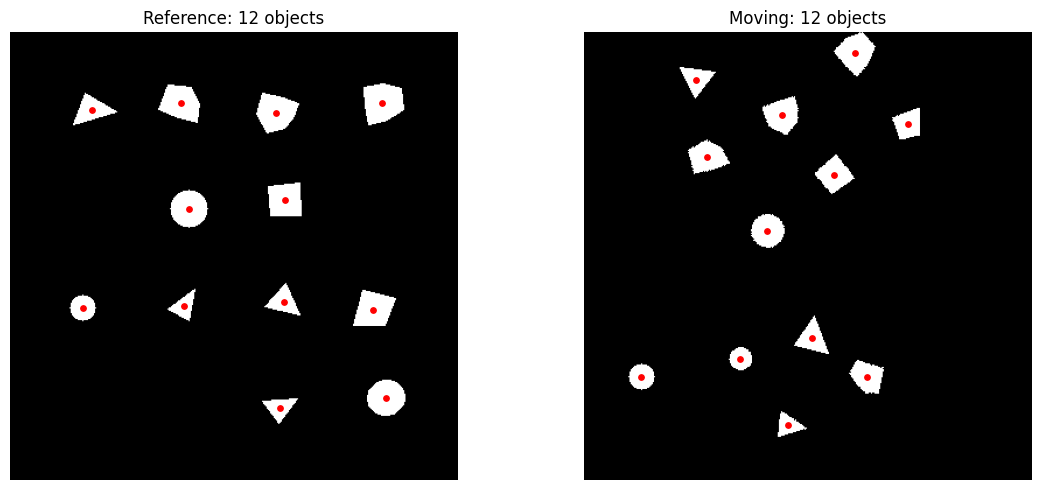

Reference objects: 12
Moving objects: 12
Actual common objects: 6


In [29]:
# Visualize a challenging registration problem

challenging_pair = make_challenging_pair(
    missing_fraction=0.25,
    extra_fraction=0.20,
    overlap_fraction=0.75,
    angle=35,
    scale=0.90,
    tx=15,
    ty=-12,
    seed=42,
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

axes[0].imshow(
    challenging_pair["reference_image"],
    cmap="gray"
)

axes[0].scatter(
    challenging_pair["ref_points"][:, 0],
    challenging_pair["ref_points"][:, 1],
    s=15,
    c="red"
)

axes[0].set_title(
    f"Reference: {len(challenging_pair['ref_ids'])} objects"
)

axes[1].imshow(
    challenging_pair["moving_image"],
    cmap="gray"
)

axes[1].scatter(
    challenging_pair["mov_points"][:, 0],
    challenging_pair["mov_points"][:, 1],
    s=15,
    c="red"
)

axes[1].set_title(
    f"Moving: {len(challenging_pair['mov_ids'])} objects"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Determine the exact number of common objects
common_ids = np.intersect1d(
    challenging_pair["ref_ids"],
    challenging_pair["mov_ids"]
)

print("Reference objects:",
      len(challenging_pair["ref_ids"]))

print("Moving objects:",
      len(challenging_pair["mov_ids"]))

print("Actual common objects:",
      len(common_ids))

## Part I: Evaluate matches using exact object identities

In [30]:
# Matching precision and recall

def evaluate_identity_matches(
    matches,
    ref_ids,
    mov_ids,
):
    """
    Evaluate correspondences using exact object IDs.

    Returns precision, recall and matching counts.
    """

    ref_ids = np.asarray(ref_ids)
    mov_ids = np.asarray(mov_ids)

    common_ids = np.intersect1d(
        ref_ids,
        mov_ids
    )

    n_possible = len(common_ids)
    n_proposed = len(matches)

    if n_proposed == 0:
        n_correct = 0
    else:
        ri = matches[:, 0].astype(int)
        mi = matches[:, 1].astype(int)

        n_correct = int(np.sum(
            ref_ids[ri] == mov_ids[mi]
        ))

    precision = (
        n_correct / n_proposed
        if n_proposed > 0
        else 0.0
    )

    recall = (
        n_correct / n_possible
        if n_possible > 0
        else np.nan
    )

    return {
        "precision": precision,
        "recall": recall,
        "n_correct": n_correct,
        "n_proposed": n_proposed,
        "n_possible": n_possible,
    }

In [31]:
# Run both methods on the same image pair

def registration_ground_truth_rmse(
    M_est,
    M_true,
    points,
):
    """
    Evaluate moving-to-reference registration using
    reference points transformed by the true model.
    """

    points = np.asarray(
        points,
        dtype=np.float32
    )

    if len(points) == 0:
        return np.nan

    moving = cv2.transform(
        points[None, :, :],
        M_true
    )[0]

    recovered = cv2.transform(
        moving[None, :, :],
        M_est
    )[0]

    errors = np.linalg.norm(
        recovered - points,
        axis=1
    )

    return float(np.sqrt(
        np.mean(errors**2)
    ))


def run_registration_experiment(
    pair,
    model,
    device,
    success_threshold=3.0,
):
    """
    Compare Methods A and B on the same synthetic pair.

    Returns
    -------
    results : list of dict
        Results for A and B.
    details : dict
        Matches and fitted transformations.
    """

    ref_points = pair["ref_points"]
    mov_points = pair["mov_points"]

    ref_ids = pair["ref_ids"]
    mov_ids = pair["mov_ids"]

    if min(len(ref_points), len(mov_points)) < 2:
        return [], {}

    ref_embeddings = compute_embeddings(
        model,
        pair["ref_patches"],
        device
    )

    mov_embeddings = compute_embeddings(
        model,
        pair["mov_patches"],
        device
    )

    # ---------------------------
    # Method A
    # ---------------------------
    matches_A = match_embeddings(
        ref_embeddings,
        mov_embeddings
    )

    # ---------------------------
    # Method B
    # ---------------------------
    ref_spatial, ref_spacing = (
        compute_spatial_descriptors(
            ref_points, k=5
        )
    )

    mov_spatial, mov_spacing = (
        compute_spatial_descriptors(
            mov_points, k=5
        )
    )

    sim = compute_combined_similarity(
        ref_embeddings,
        mov_embeddings,
        ref_spatial,
        mov_spatial,
        shape_weight=0.7,
    )

    candidates, unary, compatibility = (
        build_correspondence_graph(
            ref_points,
            mov_points,
            sim["combined"],
            scale_estimate=ref_spacing / mov_spacing,
            top_k=5,
        )
    )

    matches_B, _ = spatial_consensus_matching(
        candidates,
        unary,
        compatibility,
        n_ref=len(ref_points),
        n_mov=len(mov_points),
    )

    # Common physical objects
    common_ids = np.intersect1d(
        ref_ids,
        mov_ids
    )

    # Use all available shared reference features
    # for evaluation of transformation accuracy
    eval_points = ref_points[
        np.isin(ref_ids, common_ids)
    ]

    results = []
    details = {}

    for method_name, matches in [
        ("A", matches_A),
        ("B", matches_B),
    ]:

        t0 = time.perf_counter()

        match_metrics = evaluate_identity_matches(
            matches,
            ref_ids,
            mov_ids,
        )

        reg = None
        rmse = np.nan

        if len(matches) >= 3:

            try:
                reg = estimate_registration(
                    ref_points,
                    mov_points,
                    matches,
                    ransac_threshold=4.0,
                )

                rmse = registration_ground_truth_rmse(
                    reg["transform"],
                    pair["true_forward_transform"],
                    eval_points,
                )

            except (ValueError, RuntimeError, cv2.error):
                reg = None

        success = (
            np.isfinite(rmse)
            and rmse < success_threshold
        )

        elapsed = time.perf_counter() - t0

        results.append({
            "method": method_name,
            "n_ref": len(ref_points),
            "n_mov": len(mov_points),
            "n_common": len(common_ids),
            "precision": match_metrics["precision"],
            "recall": match_metrics["recall"],
            "n_matches": len(matches),
            "n_correct": match_metrics["n_correct"],
            "n_inliers": (
                int(reg["inliers"].sum())
                if reg is not None else 0
            ),
            "rmse": rmse,
            "success": bool(success),
            "time_seconds": elapsed,
        })

        details[method_name] = {
            "matches": matches,
            "registration": reg,
        }

    return results, details

In [32]:
# Test our challenging image pair

results, details = run_registration_experiment(
    challenging_pair,
    model,
    device,
)

display(
    pd.DataFrame(results).round(4)
)

,method,n_ref,n_mov,n_common,precision,recall,n_matches,n_correct,n_inliers,rmse,success,time_seconds
0,A,12,12,6,0.0000,0.0000,4,0,2,259.0392,False,0.0002
1,B,12,12,6,0.0833,0.1667,12,1,3,130.4646,False,0.0001


Method A


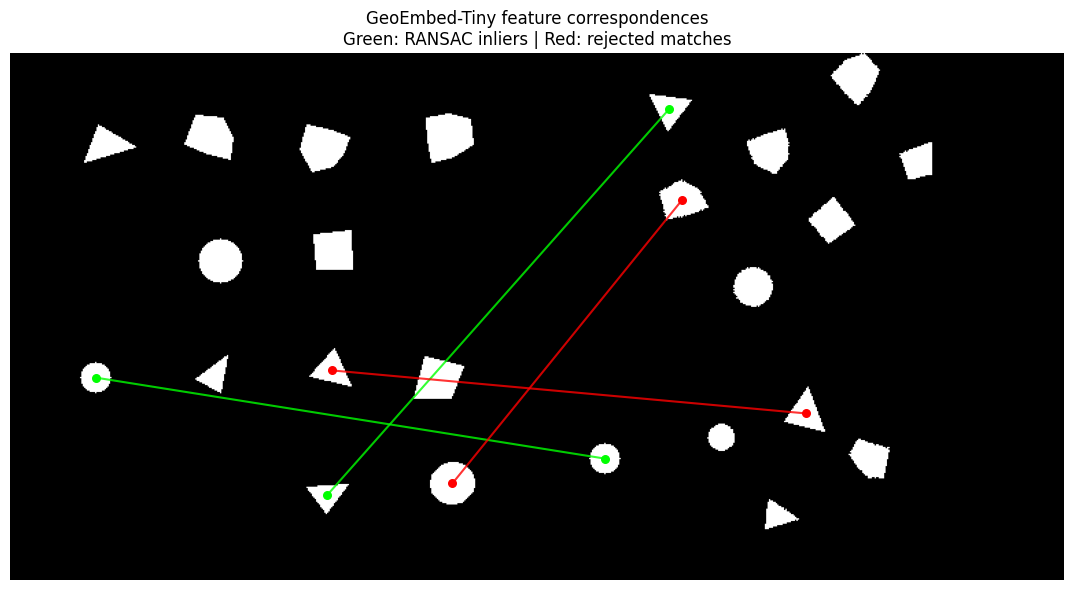

Method B


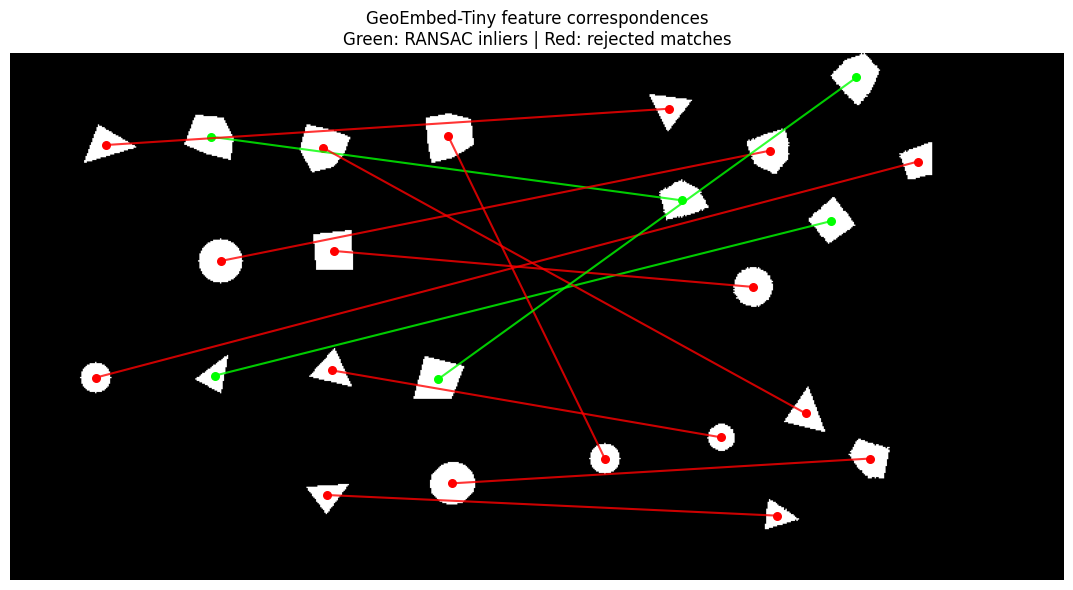

In [33]:
for method_name in ["A", "B"]:

    current = details[method_name]

    if current["registration"] is None:
        print(f"Method {method_name}: registration failed")
        continue

    print(f"Method {method_name}")

    plot_feature_matches(
        challenging_pair["reference_image"],
        challenging_pair["moving_image"],
        challenging_pair["ref_points"],
        challenging_pair["mov_points"],
        current["matches"],
        current["registration"]["inliers"],
    )

In [34]:
# Run the robustness benchmark on challenging pairs

def run_robustness_benchmark(
    model,
    device,
    n_trials=15,
    seed=2026,
):

    experiments = {
        "Missing objects": {
            "parameter": "missing_fraction",
            "values": [0.0, 0.15, 0.30, 0.45],
        },
        "Extra objects": {
            "parameter": "extra_fraction",
            "values": [0.0, 0.15, 0.30, 0.45],
        },
        "Partial overlap": {
            "parameter": "overlap_fraction",
            "values": [1.0, 0.85, 0.70, 0.55],
        },
    }

    all_results = []

    rng = np.random.default_rng(seed)

    model.eval()

    for experiment_name, config in experiments.items():

        parameter = config["parameter"]

        print(f"\nRunning: {experiment_name}")

        for value in config["values"]:

            for trial in range(n_trials):

                # Random transformation
                angle = float(
                    rng.uniform(-60, 60)
                )

                scale = float(
                    rng.uniform(0.85, 1.15)
                )

                tx, ty = rng.uniform(
                    -20, 20, size=2
                )

                kwargs = {
                    "missing_fraction": 0.0,
                    "extra_fraction": 0.0,
                    "overlap_fraction": 1.0,
                }

                kwargs[parameter] = value

                pair_seed = int(
                    rng.integers(0, 2**31 - 1)
                )

                pair = make_challenging_pair(
                    **kwargs,
                    angle=angle,
                    scale=scale,
                    tx=tx,
                    ty=ty,
                    seed=pair_seed,
                )

                results, _ = run_registration_experiment(
                    pair,
                    model,
                    device,
                )

                for result in results:

                    result.update({
                        "experiment": experiment_name,
                        "difficulty": value,
                        "trial": trial,
                    })

                    all_results.append(result)

            print(
                f"  Difficulty {value:.2f}: "
                f"{n_trials} trials complete"
            )

    return pd.DataFrame(all_results)


robustness_df = run_robustness_benchmark(
    model,
    device,
    n_trials=15,
)

print("\nTotal experiment results:", len(robustness_df))

display(robustness_df.head())


Running: Missing objects
  Difficulty 0.00: 15 trials complete
  Difficulty 0.15: 15 trials complete
  Difficulty 0.30: 15 trials complete
  Difficulty 0.45: 15 trials complete

Running: Extra objects
  Difficulty 0.00: 15 trials complete
  Difficulty 0.15: 15 trials complete
  Difficulty 0.30: 15 trials complete
  Difficulty 0.45: 15 trials complete

Running: Partial overlap
  Difficulty 1.00: 15 trials complete
  Difficulty 0.85: 15 trials complete
  Difficulty 0.70: 15 trials complete
  Difficulty 0.55: 15 trials complete

Total experiment results: 360


,method,n_ref,n_mov,n_common,precision,recall,n_matches,n_correct,n_inliers,rmse,success,time_seconds,experiment,difficulty,trial
0,A,16,15,15,0.000000,0.000000,7,0,2,276.132507,False,0.000226,Missing objects,0.0,0
1,B,16,15,15,0.928571,0.866667,14,13,12,1.101056,True,0.000104,Missing objects,0.0,0
2,A,16,14,14,0.333333,0.142857,6,2,2,285.999603,False,0.000140,Missing objects,0.0,1
3,B,16,14,14,0.833333,0.714286,12,10,8,0.012324,True,0.000086,Missing objects,0.0,1
4,A,16,14,14,0.200000,0.071429,5,1,2,316.453094,False,0.000135,Missing objects,0.0,2


In [35]:
# Summarize the robustness benchmark results

robustness_summary = (
    robustness_df
    .groupby(
        ["experiment", "difficulty", "method"]
    )
    .agg(
        success_rate=("success", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        median_rmse=("rmse", "median"),
        mean_inliers=("n_inliers", "mean"),
        mean_matches=("n_matches", "mean"),
        mean_common=("n_common", "mean"),
    )
    .reset_index()
)

display(
    robustness_summary.round(4)
)

,experiment,difficulty,method,success_rate,mean_precision,mean_recall,median_rmse,mean_inliers,mean_matches,mean_common
0,Extra objects,0.00,A,0.6000,0.4323,0.2385,0.0697,4.2667,7.4000,15.0667
1,Extra objects,0.00,B,1.0000,0.9213,0.8664,0.0358,13.0667,14.1333,15.0667
2,Extra objects,0.15,A,0.2000,0.2607,0.1401,228.4555,3.0667,7.3333,15.4000
3,Extra objects,0.15,B,0.9333,0.8162,0.6884,0.0389,10.5333,13.0667,15.4000
4,Extra objects,0.30,A,0.2000,0.2623,0.1416,218.8617,2.6667,8.0000,15.2000
5,Extra objects,0.30,B,0.2000,0.1637,0.1301,177.9335,3.3333,10.3333,15.2000
6,Extra objects,0.45,A,0.2667,0.2582,0.1376,190.1823,2.6667,7.6667,15.5333
7,Extra objects,0.45,B,0.0667,0.0749,0.0508,254.4377,2.6000,10.8000,15.5333
8,Missing objects,0.00,A,0.6000,0.5109,0.2999,0.1299,5.1333,8.2667,15.4000
9,Missing objects,0.00,B,1.0000,0.9524,0.9162,0.0368,14.0000,14.8000,15.4000


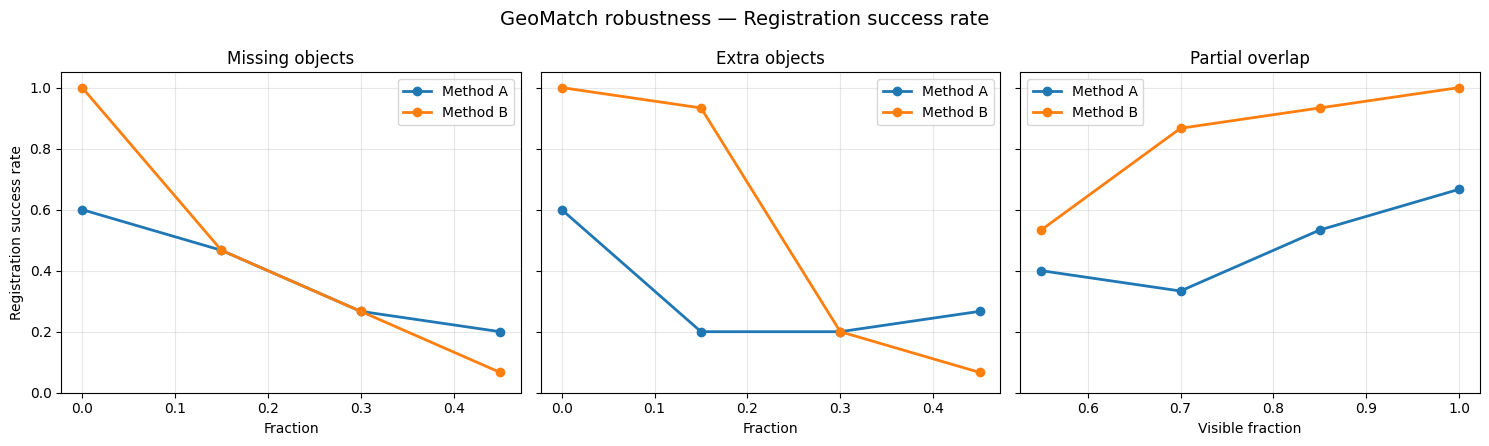

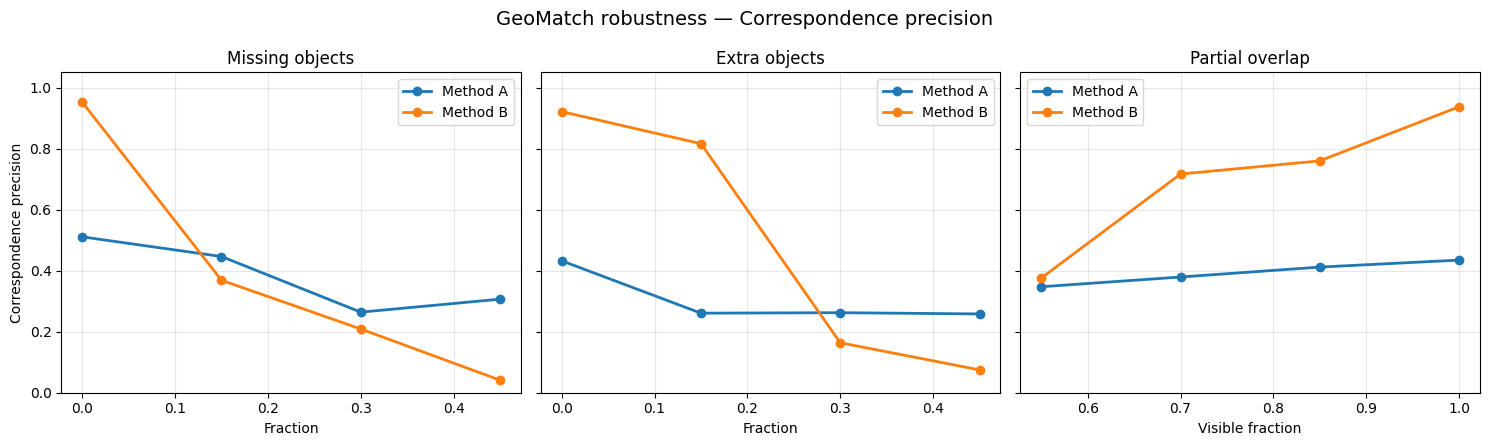

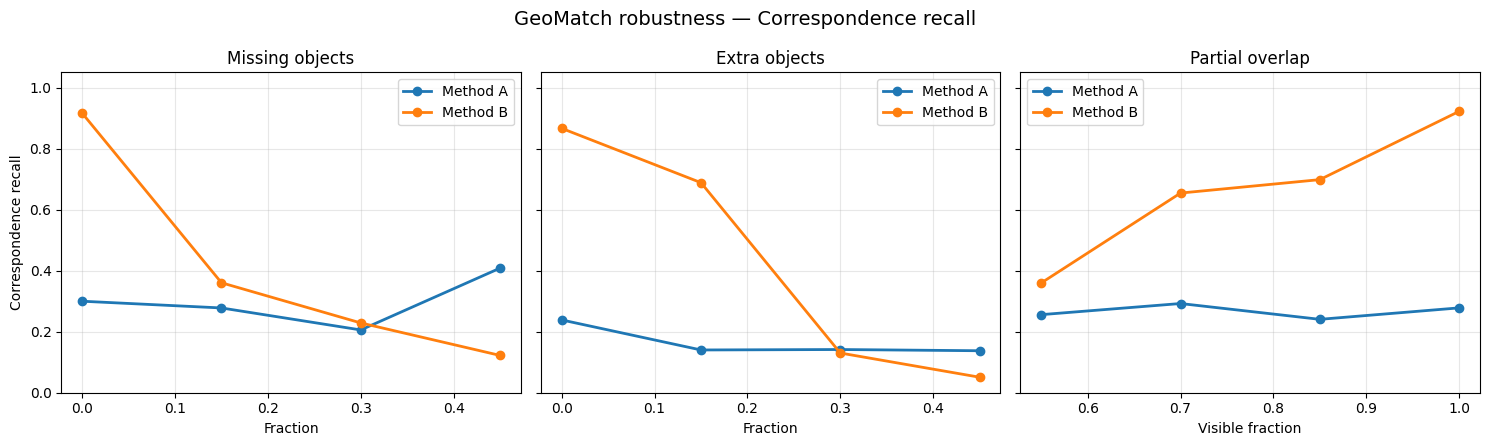

In [36]:
# Plot robustness curves

metrics = [
    ("success_rate", "Registration success rate"),
    ("mean_precision", "Correspondence precision"),
    ("mean_recall", "Correspondence recall"),
]

experiment_names = [
    "Missing objects",
    "Extra objects",
    "Partial overlap",
]

for metric, ylabel in metrics:

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4.5),
        sharey=True,
    )

    for ax, experiment in zip(
        axes, experiment_names
    ):

        subset = robustness_summary[
            robustness_summary["experiment"] == experiment
        ]

        for method in ["A", "B"]:

            data = subset[
                subset["method"] == method
            ].sort_values("difficulty")

            ax.plot(
                data["difficulty"],
                data[metric],
                marker="o",
                linewidth=2,
                label=f"Method {method}",
            )

        ax.set_title(experiment)
        ax.set_xlabel(
            "Visible fraction"
            if experiment == "Partial overlap"
            else "Fraction"
        )

        ax.grid(alpha=0.3)
        ax.legend()

        ax.set_ylim(0, 1.05)

    axes[0].set_ylabel(ylabel)

    fig.suptitle(
        f"GeoMatch robustness — {ylabel}",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()

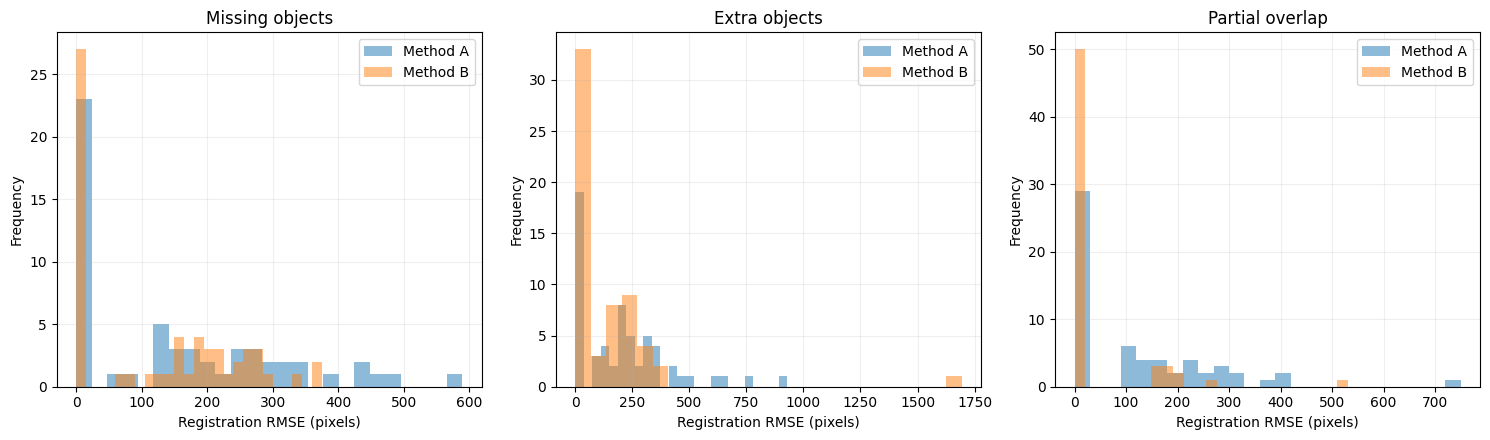

In [37]:
# Examine registration error distributions

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5)
)

for ax, experiment in zip(
    axes, experiment_names
):

    subset = robustness_df[
        robustness_df["experiment"] == experiment
    ]

    for method in ["A", "B"]:

        values = subset.loc[
            (subset["method"] == method)
            & np.isfinite(subset["rmse"]),
            "rmse"
        ].to_numpy()

        if len(values) == 0:
            continue

        ax.hist(
            values,
            bins=25,
            alpha=0.5,
            label=f"Method {method}",
        )

    ax.set_title(experiment)
    ax.set_xlabel("Registration RMSE (pixels)")
    ax.set_ylabel("Frequency")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()